In [7]:
%load_ext autoreload
%autoreload 2

import iml  # helper functions and classes (see iml/)
import numpy as np  # array processing
import pandas as pd  # dataframes, reading files
import matplotlib.pyplot as plt  # making plots

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**Group members:**
- Leandro da Silva Sousa
- Ana Beatriz Morais Branquinho
- José Miguel Macedo Granja

## Part 1: Partial Derivatives

### (a)
> Compute the derivative $\partial L / \partial x(i).$ Leaving all other
> variables fixed, what value of $x(i)$ minimizes $L$?

> $$\frac{\partial L}{\partial x(i)}=\sum_{i=1}^{N}\frac{\partial}{\partial x(i)}|\mu-x(i)|+\lambda y^2$$
> $$=\sum_{i=1}^{N}sgn(\mu-x(i))(-1)+0$$
> $$=\sum_{i=1}^{N}-sgn(\mu-x(i))$$
> $$=-sgn(\mu-x(i))$$ [since all other sum terms are not for x(i)]
> $$(\mu -x(i))>0$$
> $$=>x(i)<\mu$$
> $$=-1$$
>
> $$...<0$$
> $$=>x(i)=\mu$$
> $$=1$$
> Since for x(i), only $|\mu-x(i)|$ changes L, $x(i)=\mu$

### (b)
> Compute the derivative $\partial L / \partial \mu.$ If $\lambda = 0,$ what
> values of $\mu$ minimize $L$?

>$$=\sum_{i=1}^{N}\frac{\partial}{\partial(\mu)} |\mu-x(i)|+\lambda\mu^2$$
>$$=\sum_{i=1}^{N}sgn(\mu-x(i))1+2\lambda\mu$$
>$$=\sum_{i=1}^{N}sgn(\mu-x(i))+2\lambda\mu$$
>If we set $\lambda=0$,then:
>$$=\sum_{i=1}^{N}sgn(\mu-x(i))$$
>To minimize L, the derivate must be 0.
>we expand the sum.
>$$=sign(\mu-x(i))+sgn(\mu-x(2))+...+sgn(\mu-x(N))$$
>Each "sgn" is either -1 or 1: $\mu>x(i)=>1$,$\mu<x(i)=>-1$
>
>
>**RESPONSE: We pick the median of the values (L derivation will be 0)**
>
>
>Example:
>
>X={1,2,3}=>N=3, right of $\mu=2$
>$$\frac{\partial L}{\partial \mu}=sgn(\mu-1)+sgn(\mu-2)+sgn(\mu-3)$$
>$$=1+1-1=1$$
>X={1,2,3}=>N=3, left of $\mu=2$:
>$$1-1-1=-1$$
>
>So in this example, we would pick $\mu=2$.

### (c)
> Compute the derivative $\partial L / \partial \theta.$

>$$L=\sum_{i=1}^{N}|\theta^3-x(i)|+x\theta^6$$
>$$\frac{\partial L}{\partial\theta}=\sum_{i=1}^{N} \frac{\partial}{\partial\theta}[(\theta^3-x(i))+x\theta^6]$$
>$$=\sum_{i=1}^{N} sign(\theta^3-x(i))3\theta^2+6x\theta^5$$
>$$=\sum_{i=1}^{N} 3\theta^2(sign(\theta^3-x(i))+2\lambda\theta^3)$$
>Result:
>$$ \partial L / \partial \theta = 3\theta^2+2\lambda\theta^3\sum_{i=1 }^{N }sign(\theta^3-x(i))$$

### (d)
> Compute $$
> \frac{\partial}{\partial z_i} \ln \operatorname{softmax}(z)_j.
> $$
> (Hint: first define $Z = \ln \sum_{j = 1}^k e^{z_j}$ and compute
> $\partial Z / \partial z_j.$)

> $\frac{\partial}{\partial z_i}$ ln softmax (z)j, where:
>
> softmax(z)j$=\frac{e^{z_j}}{\sum_{l=1}^{k}e^{z_l}}$
>
>Reminder:ln$(\frac{x}{y}) = lnx-lny$
> and $ln(e^x)=x$
>
> Therefore, $\ln{(softmax (z)j)}=\ln{e^{z_j}}-\ln{\sum_{l=1}^{k}e^z_l} = z_j-\ln(\sum_{l=1}^{k}e^{z_l})$
>
> $$\frac{\partial}{\partial z_i}ln(softmax(z)j)=\frac{\partial}{\partial z_i}[z_j-ln(\sum_{l=1}^{k}e^{z_l})]$$
> $$=\frac{\partial z_j}{\partial z_i}-\frac{\partial}{\partial z_i}ln{(\sum_{l=1}^{k}e^{z_l})}$$
> $$*...$$
> Before continuing, let's compute the second term:
> $$\frac{\partial}{\partial z_i}ln(\sum_{l=1}^{k}e^{z_l})=\frac{\frac{\partial}{\partial z_i}\sum_{l=1}^{k}e^{z_l}}{\sum_ {l=1}^{k}e^{z_l}}$$
> $$=\frac{\sum_{l=1}^{k}\frac{\partial e^{z_l}}{\partial z_i}}{\sum_{l=1}^{k}e^{z_l}}$$
> $$=\frac{e^{z_i}}{\sum_{l=1}^{k}e^{z_l}}$$
> Let's continue
> $$*...=\frac{\partial z_j}{\partial z_i}-\frac{e^{z_i}}{\sum_{l=1}^{k}e^{z_l}}$$
> $$=\frac{\partial z_j}{\partial z_i}-softmax(z)i$$
> $\frac{\partial z_j}{\partial z_i}$ is also known as a "Kronecker delta", which can be expressed as $\delta_{ij}$, so our final result is:
> $$ \frac{\partial}{\partial z_i} ln(softmax (z)j) = \delta_{ij}-softmax(z)i$$

## Part 2: Linear Regression

### (a)
> Consider the linear model, defined by parameters $(\theta_0, \theta_1)$,
> which predicts $$
> \hat y(i) = \theta_0 + \theta_1 x(i)
> $$ for each index
> $i.$ Express the gradient $\nabla L$ of mean squared error as a function of
> the parameter vector $\theta$ and the datapoints $(x(i), y(i)).$

>Using what we know
> $$\hat y(i) = \theta_0 + \theta_1 x(i)$$
>$$L=\frac{1}{N}\sum_{i=1}^{N}((\hat y(i)-y(i))^2)=\frac{1}{N}\sum_{i=1}^{N}(\theta_0+\theta_1x(i)-y(i))^2$$
>let's calculate the function 
>$$\nabla L=\begin{bmatrix}
\frac{\partial L}{\partial \theta_0}\
\frac{\partial L}{\partial \theta_1}
\end{bmatrix}$$
>with:
>$$\frac{\partial L}{\partial \theta_0}=\frac{2}{N}\sum_{i=1}^{N}
(\theta_0+\theta_1x(i)-y(i))$$
>and
>$$\frac{\partial L}{\partial \theta_1}=\frac{2}{N}\sum_{i=1}^{N}
(\theta_0+\theta_1x(i)-y(i))x(i)$$


In [10]:
x, y = iml.load_powerplant()

### (b)
> Extend the `SimpleRegressor` class from `iml/simple_regressor.py`,
> implementing the method `fit(self, x, y, lr, steps)` to implement gradient
> descent on mean squared error. Run `fit()` on the _unnormalized_ data
> vectors `x` and `y`, and show the training process over 20 iterations with
> `SimpleRegressor.show_training()`. Find a learning rate that makes the loss
> decrease.

In [ ]:
#changed only this part of the function
        for i in range(steps):
            # here: update self.weights_?
            errors = self.predict(x) - y
            
            gradient_theta0 = 2 * np.mean(errors)
            gradient_theta1 = 2 * np.mean(errors * x)
            
            self.weights_[0] -= lr * gradient_theta0
            self.weights_[1] -= lr * gradient_theta1
            self.y_predicted_[i + 1] = self.predict(x)

In [11]:
regressor = SimpleRegressor()
regressor.fit(x, y, lr=0.00001, steps=20)
regressor.show_training()

NameError: name 'SimpleRegressor' is not defined

### (c)
> Now, normalize your data in some way and run `fit()` and `show_training()`
> again, ensuring that you converge to an acceptable model in 20 iterations.

In [ ]:
x_norm = (x - np.min(x)) / (np.max(x) - np.min(x))
y_norm = (y - np.min(y)) / (np.max(y) - np.min(y))
regressor_norm = SimpleRegressor()

regressor_norm.fit(x_norm, y_norm, lr=0.1, steps=20)

regressor_norm.show_training()

## Part 3: k-Means and PCA

In [8]:
from sklearn.datasets import load_iris
iris = load_iris()
ulu = iml.load_ulu()

### (a)
> Suppose we didn't have access to the species attribute of the iris dataset.
> Implement the Lloyd-Forgy algorithm for $k$-means and use it to infer a
> partition of the iris dataset into three species. Compute the confusion
> matrix and the accuracy of the partition relative to the true species.

In [12]:
iris.data.shape

(150, 4)

### (b)
> Investigate `data/ulu.csv` using PCA and explain how this dataset was
> produced. Using scikit-learn, run both $k$-means clustering and DBSCAN on
> this dataset. Which method produces more reasonable "clusters"?

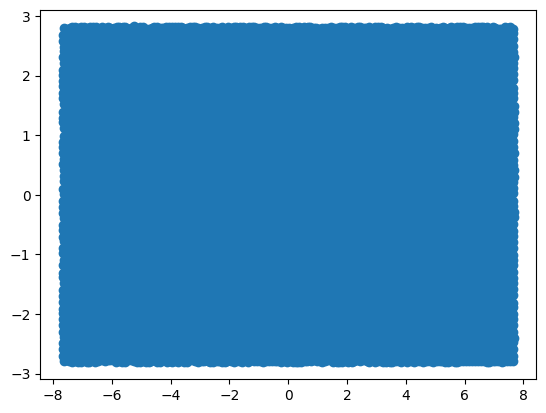

[3 5 3 ... 0 5 2]
[0 1 1 ... 1 1 1]


In [26]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(ulu)

plt.scatter(X_pca[:,0], X_pca[:,1])
plt.show()

# KMeans
kmeans = KMeans()
k_labels = kmeans.fit_predict(ulu)
print(k_labels)

# DBSCAN
dbscan = DBSCAN()
d_labels = dbscan.fit_predict(ulu)
print(d_labels)